# Insurance Missing Values Analysis

**Objective:** Analyze missing value patterns in an insurance-style dataset and identify columns that require dropping, imputation, or further business review before modeling/reporting.

In [1]:
import pandas as pd
import numpy as np
import re
import seaborn as sns
import plotly.express as px
import warnings
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("data/insurance_sample.csv")

In [3]:
df

,Date,Product,Gross_Premium,Total_Incl_VAT,City,Payment_Status,Payment_Method,Policy_Start_Date,Policy_Term,Policy_Duration_Days,Policy_End_Date,Customer_ID
0,2025-02-02,Travel,854.0,1007.72,Los Angeles,Pending,Online,2025-02-02,1Y,365,2026-02-01,CUST0001
1,2025-10-09,Travel,921.0,1086.78,Los Angeles,Paid,Card,2025-10-09,1Y,365,2026-10-08,CUST0002
2,2025-08-27,Medical,858.0,1012.44,New York,Paid,Online,2025-08-27,1M,30,2025-09-25,CUST0003
3,2025-06-09,Motor,771.0,909.78,Chicago,Paid,Online,2025-06-09,1Y,365,2026-06-08,CUST0004
4,2025-06-07,Medical,822.0,969.96,Los Angeles,Paid,Cash,2025-06-07,1Y,365,2026-06-06,CUST0005
...,...,...,...,...,...,...,...,...,...,...,...,...
1995,2025-01-01,Medical,787.0,928.66,Chicago,Pending,Bank Transfer,2025-01-01,1Y,365,2025-12-31,CUST1996
1996,2025-07-21,Medical,886.0,1045.48,Atlanta,Paid,Card,2025-07-21,1Y,365,2026-07-20,CUST1997
1997,2025-12-28,Medical,715.0,843.70,Chicago,Paid,Online,2025-12-28,1Y,365,2026-12-27,CUST1998
1998,2025-04-13,Travel,855.0,1008.90,New York,Paid,Bank Transfer,2025-04-13,1Y,365,2026-04-12,CUST1999


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  2000 non-null   object 
 1   Product               2000 non-null   object 
 2   Gross_Premium         1950 non-null   float64
 3   Total_Incl_VAT        1950 non-null   float64
 4   City                  1980 non-null   object 
 5   Payment_Status        1970 non-null   object 
 6   Payment_Method        2000 non-null   object 
 7   Policy_Start_Date     2000 non-null   object 
 8   Policy_Term           2000 non-null   object 
 9   Policy_Duration_Days  2000 non-null   int64  
 10  Policy_End_Date       2000 non-null   object 
 11  Customer_ID           2000 non-null   object 
dtypes: float64(2), int64(1), object(9)
memory usage: 187.6+ KB


In [5]:
df.isnull().sum()

Date                     0
Product                  0
Gross_Premium           50
Total_Incl_VAT          50
City                    20
Payment_Status          30
Payment_Method           0
Policy_Start_Date        0
Policy_Term              0
Policy_Duration_Days     0
Policy_End_Date          0
Customer_ID              0
dtype: int64

In [10]:
# Show total and percentage of missing values
missing_info = df.isnull().sum().to_frame(name='Missing Count')
missing_info['Missing %'] = (df.isnull().mean() * 100).round(2)
missing_info = missing_info[missing_info['Missing Count'] > 0]
missing_info.sort_values(by='Missing %', ascending=False)


,Missing Count,Missing %
Gross_Premium,50,2.5
Total_Incl_VAT,50,2.5
Payment_Status,30,1.5
City,20,1.0


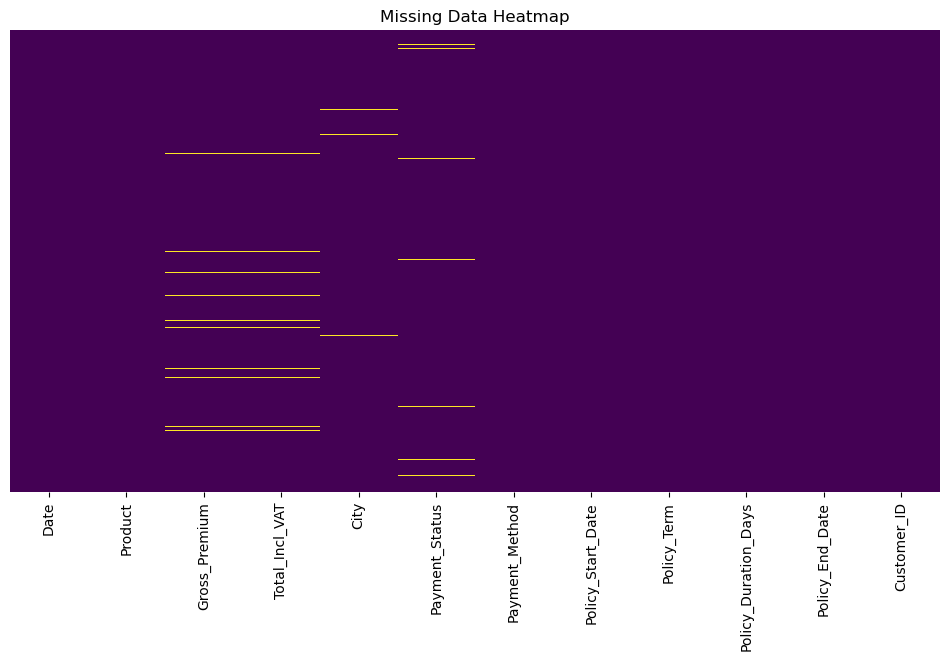

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Data Heatmap')
plt.show()


In [9]:
# Calculate mean, median, and mode
mean_premium = df['Gross_Premium'].mean()
median_premium = df['Gross_Premium'].median()
mode_premium = df['Gross_Premium'].mode()[0]

print(f"Mean Gross Premium: {mean_premium:.2f}")
print(f"Median Gross Premium: {median_premium:.2f}")
print(f"Most Frequent (Mode) Gross Premium: {mode_premium}")


Mean Gross Premium: 898.91
Median Gross Premium: 897.50
Most Frequent (Mode) Gross Premium: 972.0


In [11]:

# 1) Fill missing Gross_Premium with mean
gross_mean = df["Gross_Premium"].mean(skipna=True)
df["Gross_Premium"] = df["Gross_Premium"].fillna(gross_mean)

# 2) Estimate VAT multiplier from existing non-missing rows
valid_mask = (
    df["Gross_Premium"].notna() &
    df["Total_Incl_VAT"].notna() &
    (df["Gross_Premium"] > 0)
)

vat_multiplier = (df.loc[valid_mask, "Total_Incl_VAT"] / df.loc[valid_mask, "Gross_Premium"]).median()

# If ratio cannot be calculated for any reason, use a default (example: 1.05 for 5% VAT)
if pd.isna(vat_multiplier):
    vat_multiplier = 1.05

# 3) Fill missing Total_Incl_VAT using Gross_Premium * VAT multiplier
df["Total_Incl_VAT"] = df["Total_Incl_VAT"].fillna(df["Gross_Premium"] * vat_multiplier)

# 4) Optional: round numeric columns
df["Gross_Premium"] = df["Gross_Premium"].round(2)
df["Total_Incl_VAT"] = df["Total_Incl_VAT"].round(2)

# 5) Check remaining missing values
print(df[["Gross_Premium", "Total_Incl_VAT", "Payment_Status", "City"]].isna().sum())

Gross_Premium      0
Total_Incl_VAT     0
Payment_Status    30
City              20
dtype: int64


In [12]:

# 1) Check missing count
print("Missing Payment_Status:", df["Payment_Status"].isna().sum())

# 2) Frequency of Payment_Method
print("\nPayment_Method value counts:")
print(df["Payment_Method"].value_counts(dropna=False))

# 3) Frequency of Payment_Status
print("\nPayment_Status value counts:")
print(df["Payment_Status"].value_counts(dropna=False))

# 4) Crosstab: Payment_Method vs Payment_Status (counts)
ct_count = pd.crosstab(
    df["Payment_Method"],
    df["Payment_Status"],
    dropna=False
)

print("\nCrosstab (count):")
print(ct_count)

# 5) Crosstab row-wise percentage (helps to see dominant status per method)
ct_pct = pd.crosstab(
    df["Payment_Method"],
    df["Payment_Status"],
    normalize="index",
    dropna=False
).round(3)

print("\nCrosstab (row %):")
print(ct_pct)

# 6) Look only at rows where Payment_Status is missing
missing_status_rows = df[df["Payment_Status"].isna()][["Payment_Method", "Payment_Status"]].copy()

print("\nMissing Payment_Status rows grouped by Payment_Method:")
print(missing_status_rows["Payment_Method"].value_counts(dropna=False))

Missing Payment_Status: 30

Payment_Method value counts:
Payment_Method
Card             859
Bank Transfer    416
Online           403
Cash             322
Name: count, dtype: int64

Payment_Status value counts:
Payment_Status
Paid        1375
Pending      339
Failed       173
Refunded      83
NaN           30
Name: count, dtype: int64

Crosstab (count):
Payment_Status  Failed  Paid  Pending  Refunded  NaN
Payment_Method                                      
Bank Transfer       39   284       70        15    8
Card                67   588      149        43   12
Cash                34   211       59        13    5
Online              33   292       61        12    5

Crosstab (row %):
Payment_Status  Failed   Paid  Pending  Refunded    NaN
Payment_Method                                         
Bank Transfer    0.094  0.683    0.168     0.036  0.019
Card             0.078  0.685    0.173     0.050  0.014
Cash             0.106  0.655    0.183     0.040  0.016
Online           0.082  0.

In [13]:
# Fill missing Payment_Status with custom rule
missing_status_mask = df["Payment_Status"].isna()

# 1) Missing + Cash -> Failed
cash_missing_mask = missing_status_mask & (df["Payment_Method"] == "Cash")
df.loc[cash_missing_mask, "Payment_Status"] = "Failed"

# 2) Remaining missing -> Paid
remaining_missing_mask = df["Payment_Status"].isna()
df.loc[remaining_missing_mask, "Payment_Status"] = "Paid"

# Check result
print("Remaining missing Payment_Status:", df["Payment_Status"].isna().sum())

print("\nFilled rows by rule:")
print("Cash -> Failed:", cash_missing_mask.sum())
print("Other methods -> Paid:", remaining_missing_mask.sum())

print("\nUpdated Payment_Status counts:")
print(df["Payment_Status"].value_counts(dropna=False))

Remaining missing Payment_Status: 0

Filled rows by rule:
Cash -> Failed: 5
Other methods -> Paid: 25

Updated Payment_Status counts:
Payment_Status
Paid        1400
Pending      339
Failed       178
Refunded      83
Name: count, dtype: int64


In [14]:
# Fill missing City values with "Other"
df["City"] = df["City"].fillna("Other")

# Check
print("Remaining missing City:", df["City"].isna().sum())
print("\nCity value counts:")
print(df["City"].value_counts(dropna=False))

Remaining missing City: 0

City value counts:
City
New York       411
Los Angeles    294
Chicago        209
Miami          208
Houston        169
Phoenix        168
Dallas         149
Seattle        138
Atlanta        134
Boston         100
Other           20
Name: count, dtype: int64


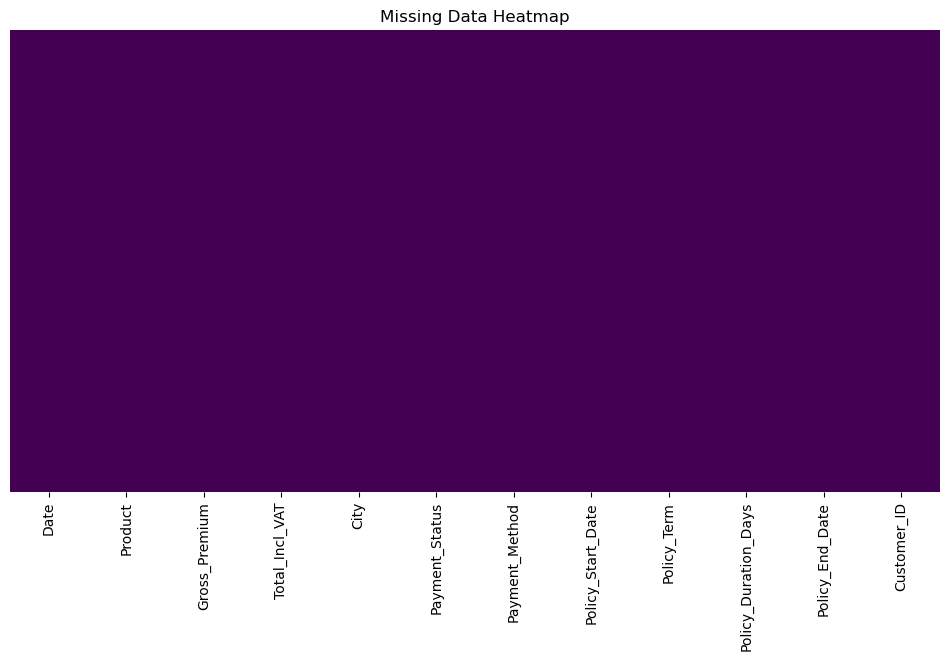

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Data Heatmap')
plt.show()
